<a href="https://colab.research.google.com/github/Hadeel-93/HW-7/blob/main/HW_7_Q2_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu


100%|██████████| 170M/170M [38:26<00:00, 73.9kB/s]


Training images: 45000
Validation images: 5000
Test images: 10000
CIFAR10_10LayerMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): ReLU()
    (7): Linear(in_features=128, out_features=64, bias=True)
    (8): ReLU()
    (9): Linear(in_features=64, out_features=64, bias=True)
    (10): ReLU()
    (11): Linear(in_features=64, out_features=64, bias=True)
    (12): ReLU()
    (13): Linear(in_features=64, out_features=64, bias=True)
    (14): ReLU()
    (15): Linear(in_features=64, out_features=64, bias=True)
    (16): ReLU()
    (17): Linear(in_features=64, out_features=64, bias=True)
    (18): ReLU()
    (19): Linear(in_features=64, out_features=64, bias=True)
    (20): ReLU()
    (21): Linear(in_features=64, out_features=10, bias=True)
  )
)



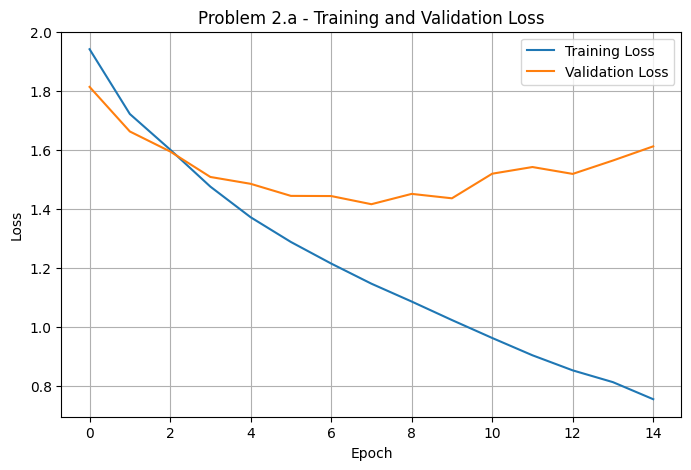

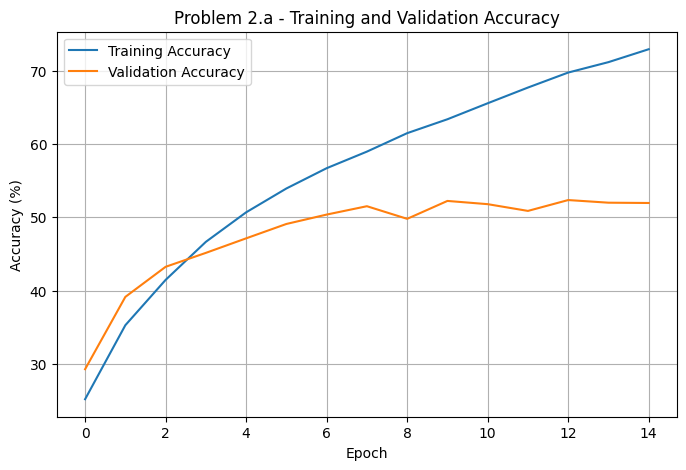

,Best Epoch,Training Time (seconds),Training Loss,Training Accuracy (%),Test Loss,Evaluation Accuracy (%),Trainable Parameters
0,8,302.373742,1.054524,62.664444,1.392157,52.28,1771466


Model and results saved successfully.


In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

import numpy as np
import time
import copy
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Same preprocessing as Problem 1.b
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

# Load CIFAR-10
full_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Same 90/10 training-validation split
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))


# 10-hidden-layer fully connected neural network
class CIFAR10_10LayerMLP(nn.Module):
    def __init__(self):
        super(CIFAR10_10LayerMLP, self).__init__()

        layers = [nn.Flatten()]

        # Hidden layer sizes
        hidden_sizes = [
            512, 256, 128,
            64, 64, 64, 64, 64, 64, 64
        ]

        input_size = 3072

        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(input_size, hidden_size))
            layers.append(nn.ReLU())
            input_size = hidden_size

        # Output layer
        layers.append(nn.Linear(input_size, 10))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


model = CIFAR10_10LayerMLP().to(device)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(model)
print(f"\nTotal trainable parameters: {total_params:,}")


# Training configuration
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

NUM_EPOCHS = 100
PATIENCE = 7

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_model_weights = None


# Calculate loss and accuracy
def calculate_metrics(model, data_loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    average_loss = total_loss / total
    accuracy = 100 * correct / total

    return average_loss, accuracy


# Training loop
start_time = time.perf_counter()

for epoch in range(NUM_EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = 100 * correct / total

    # Validation
    epoch_val_loss, epoch_val_accuracy = calculate_metrics(
        model, val_loader, criterion
    )

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_accuracy)
    val_accuracies.append(epoch_val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Accuracy: {epoch_train_accuracy:.2f}% | "
        f"Validation Loss: {epoch_val_loss:.4f} | "
        f"Validation Accuracy: {epoch_val_accuracy:.2f}%"
    )

    # Save best checkpoint
    if epoch_val_loss < best_val_loss - 0.0001:
        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1
        best_model_weights = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch + 1}.")
        break


training_time = time.perf_counter() - start_time

# Restore best model
if best_model_weights is None:
    raise RuntimeError("No valid model checkpoint was saved.")

model.load_state_dict(best_model_weights)

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print(f"Training time: {training_time:.2f} seconds")


# Final training and test metrics
final_train_loss, final_train_accuracy = calculate_metrics(
    model, train_loader, criterion
)

test_loss, test_accuracy = calculate_metrics(
    model, test_loader, criterion
)

print("\n========== Problem 2.a Results ==========")
print("Best epoch:", best_epoch)
print(f"Training time: {training_time:.2f} seconds")
print(f"Training loss: {final_train_loss:.4f}")
print(f"Training accuracy: {final_train_accuracy:.2f}%")
print(f"Test loss: {test_loss:.4f}")
print(f"Evaluation accuracy: {test_accuracy:.2f}%")
print(f"Trainable parameters: {total_params:,}")


# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Problem 2.a - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Problem 2.a - Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Save model and results
torch.save(model.state_dict(), "cifar10_10layer_mlp.pth")

results_2a = {
    "Best Epoch": best_epoch,
    "Training Time (seconds)": training_time,
    "Training Loss": final_train_loss,
    "Training Accuracy (%)": final_train_accuracy,
    "Test Loss": test_loss,
    "Evaluation Accuracy (%)": test_accuracy,
    "Trainable Parameters": total_params
}

results_df = pd.DataFrame([results_2a])
display(results_df)

results_df.to_csv("problem_2a_results.csv", index=False)

print("Model and results saved successfully.")


In [2]:
# ============================================================
# Train the 10-hidden-layer FCNN for exactly 100 epochs
# ============================================================

import time

num_epochs = 100

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    # Store results
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1:3d}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

training_time = time.time() - start_time

print("\n============================================")
print("Training completed for 100 epochs")
print("============================================")
print(f"Training time: {training_time:.2f} seconds")
print(f"Final training loss: {train_losses[-1]:.4f}")
print(f"Final training accuracy: {train_accuracies[-1]:.2f}%")
print(f"Final validation loss: {val_losses[-1]:.4f}")
print(f"Final validation accuracy: {val_accuracies[-1]:.2f}%")

Epoch [  1/100] | Train Loss: 1.0265 | Train Acc: 63.60% | Val Loss: 1.4466 | Val Acc: 50.78%
Epoch [  2/100] | Train Loss: 0.9791 | Train Acc: 64.74% | Val Loss: 1.4605 | Val Acc: 51.80%
Epoch [  3/100] | Train Loss: 0.9377 | Train Acc: 66.58% | Val Loss: 1.4908 | Val Acc: 51.22%
Epoch [  4/100] | Train Loss: 0.8941 | Train Acc: 68.09% | Val Loss: 1.5335 | Val Acc: 50.86%
Epoch [  5/100] | Train Loss: 0.8557 | Train Acc: 69.68% | Val Loss: 1.5490 | Val Acc: 51.94%
Epoch [  6/100] | Train Loss: 0.8068 | Train Acc: 71.11% | Val Loss: 1.5648 | Val Acc: 51.78%
Epoch [  7/100] | Train Loss: 0.7649 | Train Acc: 72.67% | Val Loss: 1.6386 | Val Acc: 51.76%
Epoch [  8/100] | Train Loss: 0.7307 | Train Acc: 73.99% | Val Loss: 1.5980 | Val Acc: 51.34%
Epoch [  9/100] | Train Loss: 0.6861 | Train Acc: 75.55% | Val Loss: 1.7053 | Val Acc: 52.16%
Epoch [ 10/100] | Train Loss: 0.6544 | Train Acc: 76.96% | Val Loss: 1.7507 | Val Acc: 51.06%
Epoch [ 11/100] | Train Loss: 0.6097 | Train Acc: 78.50% | V

In [3]:
# ============================================================
# Final evaluation on the official CIFAR-10 test set
# ============================================================

model.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():

    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_loss = test_loss / test_total
test_accuracy = 100 * test_correct / test_total

print("\n============================================")
print("Final Test / Evaluation Results")
print("============================================")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2f}%")


Final Test / Evaluation Results
Test loss: 3.2307
Test accuracy: 51.56%


In [4]:
# ============================================================
# Total trainable parameters
# ============================================================

total_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\n============================================")
print("Model Information")
print("============================================")
print(f"Total trainable parameters: {total_parameters:,}")


Model Information
Total trainable parameters: 1,771,466


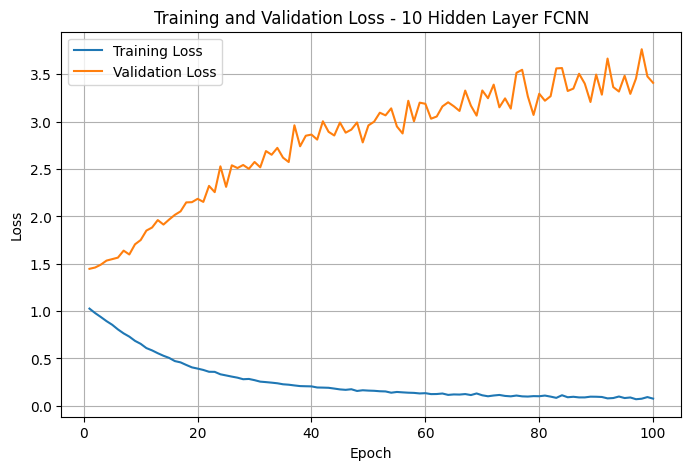

In [5]:
# ============================================================
# Plot Training and Validation Loss
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(range(1, num_epochs + 1), train_losses, label='Training Loss')
plt.plot(range(1, num_epochs + 1), val_losses, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss - 10 Hidden Layer FCNN')
plt.legend()
plt.grid(True)

plt.show()

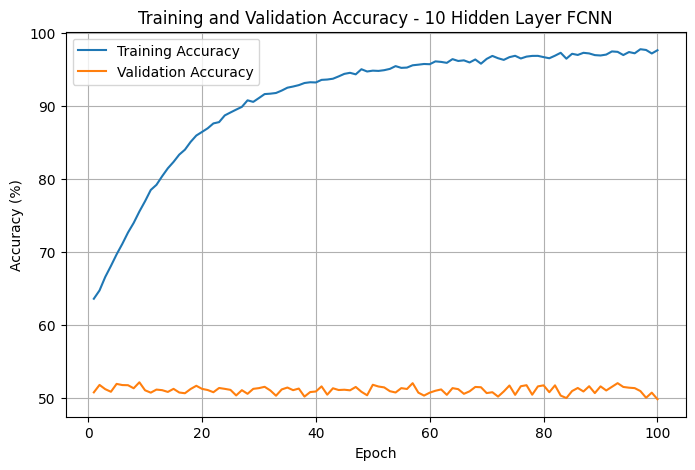

In [6]:
# ============================================================
# Plot Training and Validation Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(range(1, num_epochs + 1), train_accuracies, label='Training Accuracy')
plt.plot(range(1, num_epochs + 1), val_accuracies, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training and Validation Accuracy - 10 Hidden Layer FCNN')
plt.legend()
plt.grid(True)

plt.show()